# PyTorch — L’essentiel du framework

**Objectifs :**
- comprendre les `Tensor` ;
- utiliser `Autograd` ;
- construire un modèle avec `nn.Module` ;
- définir un `Loss` et un `Optimizer` ;
- écrire une boucle d’apprentissage ;
- distinguer `train()` et `eval()` ;
- utiliser `Dataset` / `DataLoader` ;
- entraîner un exemple de régression et un exemple de classification ;
- sauvegarder et recharger un modèle.

## 0. Préparation

Le notebook fonctionne sur CPU. S’il existe un GPU CUDA, PyTorch pourra l’utiliser automatiquement.

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

PyTorch version: 2.14.1+cu130
CUDA disponible: False


## 1. Workflow général

Le cycle de base est :

**Données → Tensors → Modèle → Prédictions → Loss → Backward → Optimizer → Mise à jour**

In [2]:
# Pseudo-code de la logique générale
# y_pred = model(X)
# loss = criterion(y_pred, y)
# optimizer.zero_grad()
# loss.backward()
# optimizer.step()

## 2. Les Tensors

Un `Tensor` est la structure de données fondamentale de PyTorch.

In [3]:
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

print("scalar:", scalar, "shape =", scalar.shape)
print("vector:", vector, "shape =", vector.shape)
print("matrix:", matrix, "shape =", matrix.shape)
print("dtype:", matrix.dtype)
print("ndim:", matrix.ndim)

scalar: tensor(3.) shape = torch.Size([])
vector: tensor([1., 2., 3.]) shape = torch.Size([3])
matrix: tensor([[1., 2.],
        [3., 4.]]) shape = torch.Size([2, 2])
dtype: torch.float32
ndim: 2


### Manipulation de Tensors

In [4]:
x = torch.arange(12)
print("x =", x)

x2 = x.reshape(3, 4)
print("reshape(3,4):", x2)

print("Colonne 1:", x2[:, 1])
print("Ligne 0:", x2[0, :])

A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[2., 0.], [1., 2.]])
print("A @ B =", A @ B)

print("mean(A) =", A.mean())
print("sum(A) =", A.sum())

x = tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
reshape(3,4): tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
Colonne 1: tensor([1, 5, 9])
Ligne 0: tensor([0, 1, 2, 3])
A @ B = tensor([[ 4.,  4.],
        [10.,  8.]])
mean(A) = tensor(2.5000)
sum(A) = tensor(10.)


## 3. CPU, GPU et `device`

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé:", device)

x = torch.tensor([1.0, 2.0, 3.0]).to(device)
print("x.device =", x.device)

Device utilisé: cpu
x.device = cpu


## 4. Autograd

`Autograd` calcule automatiquement les dérivées à partir du graphe de calcul.

In [6]:
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2

loss.backward()

print("y =", y.item())
print("loss =", loss.item())
print("dLoss/dw =", w.grad.item())
print("dLoss/db =", b.grad.item())

y = 7.0
loss = 9.0
dLoss/dw = -12.0
dLoss/db = -6.0


In [7]:
import torch

x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2

dw, db = torch.autograd.grad(loss, (w, b))

print("y =", y.item())
print("loss =", loss.item())
print("dLoss/dw =", dw.item())
print("dLoss/db =", db.item())

y = 7.0
loss = 9.0
dLoss/dw = -12.0
dLoss/db = -6.0


### Vérification analytique

Ici :

\[
y = wx+b
\]

et

\[
L=(y-10)^2
\]

Donc :

\[

rac{\partial L}{\partial w}=2(y-10)x
\]

\[

rac{\partial L}{\partial b}=2(y-10)
\]

In [8]:
y_val = (3.0 * 2.0 + 1.0)
dL_dw = 2 * (y_val - 10) * 2.0
dL_db = 2 * (y_val - 10)
print(dL_dw, dL_db)

-12.0 -6.0


## 5. Un neurone avec `nn.Linear`

Un neurone linéaire calcule essentiellement :

\[
z = \sum_i w_i x_i + b
\]

In [9]:
model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie:", y)
print("Poids:", model.weight)
print("Biais:", model.bias)

Sortie: tensor([[-0.0048]], grad_fn=<AddmmBackward0>)
Poids: Parameter containing:
tensor([[ 0.1549,  0.2261, -0.2615]], requires_grad=True)
Biais: Parameter containing:
tensor([0.1726], requires_grad=True)


In [10]:
import torch
import torch.nn as nn
from torchviz import make_dot

model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie:", y)
print("Poids:", model.weight)
print("Biais:", model.bias)

dot = make_dot(y, params=dict(model.named_parameters()))
dot.render("graphe_operations", format="png", cleanup=True)

Sortie: tensor([[2.1518]], grad_fn=<AddmmBackward0>)
Poids: Parameter containing:
tensor([[0.2030, 0.4681, 0.2260]], requires_grad=True)
Biais: Parameter containing:
tensor([0.3346], requires_grad=True)


'graphe_operations.png'

## 6. Construire un réseau avec `nn.Module`

In [11]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )

    def forward(self, x):
        return self.net(x)

model = MLP()
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


In [12]:
model = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)


## 7. Fonctions d’activation

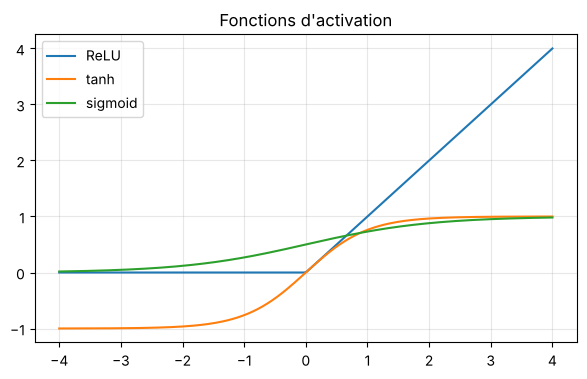

In [13]:
x = torch.linspace(-4, 4, 200)
relu = torch.relu(x)
tanh = torch.tanh(x)
sigmoid = torch.sigmoid(x)

plt.figure(figsize=(7,4))
plt.plot(x.numpy(), relu.numpy(), label='ReLU')
plt.plot(x.numpy(), tanh.numpy(), label='tanh')
plt.plot(x.numpy(), sigmoid.numpy(), label='sigmoid')
plt.grid(True, alpha=0.3)
plt.legend()
plt.title("Fonctions d'activation")
plt.show()

## 8. Forward propagation

L’appel `model(X)` déclenche automatiquement `model.forward(X)`.

In [14]:
X = torch.randn(5, 4)
# L’appel model(X) déclenche automatiquement model.forward(X)
predicted = model(X)
print("Shape entrée :", X.shape)
print("Shape sortie :", predicted.shape)

Shape entrée : torch.Size([5, 4])
Shape sortie : torch.Size([5, 3])


## 9. Fonctions de coût

Cas principaux :
- régression : `nn.MSELoss()` ;
- classification multi-classe : `nn.CrossEntropyLoss()` ;
- classification binaire : `nn.BCEWithLogitsLoss()`.

In [15]:
# Régression
criterion_reg = nn.MSELoss()
y_pred = torch.tensor([[2.0], [4.0]])
y_true = torch.tensor([[3.0], [5.0]])
print("MSE =", criterion_reg(y_pred, y_true).item())

# Classification multi-classe
criterion_cls = nn.CrossEntropyLoss()
pred = torch.tensor([[2.0, 1.0, 0.5], [0.2, 0.1, 2.0]])
y = torch.tensor([0, 2])
print("CrossEntropy =", criterion_cls(pred, y).item())

MSE = 1.0
CrossEntropy = 0.36905235052108765


## 10. Optimizers

L’optimiseur utilise les gradients pour mettre à jour les paramètres.

In [16]:
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


## 11. La boucle d’apprentissage

C’est le cœur de PyTorch.

In [17]:
X = torch.randn(8, 1)
y = 2 * X + 1
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
criterion = nn.MSELoss()
epochs = 500
# Exemple générique
for epoch in range(epochs):
    simple_model.train()
    y_pred = simple_model(X)
    loss = criterion(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 100 ==0 : 
        print(f"epoch={epoch} loss={loss.item():.4f}")

epoch=0 loss=4.1658
epoch=100 loss=0.8923
epoch=200 loss=0.1222
epoch=300 loss=0.0096
epoch=400 loss=0.0004


## 12. `train()` vs `eval()`

`model.train()` et `model.eval()` influencent notamment le comportement de `Dropout` et `BatchNorm`.

`eval()` ne désactive pas le calcul des gradients. Pour l’inférence, on utilise généralement `torch.inference_mode()`.

In [18]:
class DropoutDemo(nn.Module):
    def __init__(self):
        super().__init__()
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        return self.dropout(x)

m = DropoutDemo()
x = torch.ones(10)

m.train()
print("train() :", m(x))

m.eval()
with torch.inference_mode():
    print("eval()  :", m(x))

train() : tensor([2., 0., 0., 0., 2., 2., 0., 0., 2., 2.])
eval()  : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


## 13. Dataset et DataLoader

In [19]:
X = torch.randn(100, 3)
y = torch.randn(100, 1)

dataset = TensorDataset(X, y)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

for X_batch, y_batch in loader:
    print("Batch X:", X_batch.shape, "Batch y:", y_batch.shape)
    break

Batch X: torch.Size([16, 3]) Batch y: torch.Size([16, 1])


# Partie pratique 1 — Régression linéaire

Nous générons des données proches de :

\[
y = 3x + 2 + bruit
\]

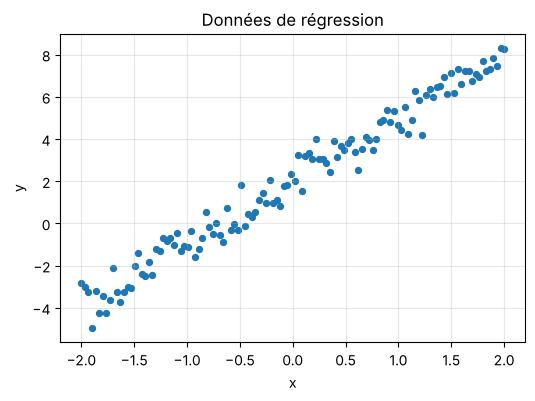

In [20]:
torch.manual_seed(42)

X = torch.linspace(-2, 2, 120).unsqueeze(1)
noise = 0.6 * torch.randn_like(X)
y = 3 * X + 2 + noise

plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18)
plt.title("Données de régression")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

## 14. Modèle, loss et optimizer

In [21]:
model_reg = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_reg.parameters(), lr=0.05)

## 15. Entraînement de la régression

In [22]:
losses = []

for epoch in range(300):
    model_reg.train()

    y_pred = model_reg(X)
    loss = criterion(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

print("Dernier loss:", losses[-1])
print("w appris:", model_reg.weight.item())
print("b appris:", model_reg.bias.item())

Dernier loss: 0.3438417613506317
w appris: 2.9894580841064453
b appris: 2.030014991760254


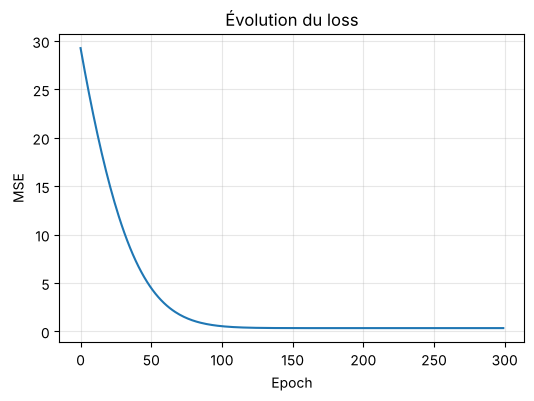

In [23]:
plt.figure(figsize=(6,4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Évolution du loss")
plt.grid(True, alpha=0.3)
plt.show()

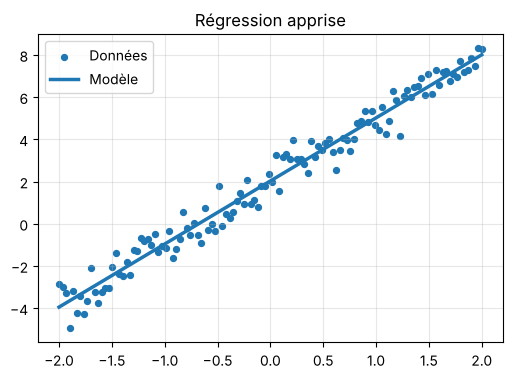

In [24]:
model_reg.eval()
with torch.inference_mode():
    y_hat = model_reg(X)

plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18, label="Données")
plt.plot(X.numpy(), y_hat.numpy(), linewidth=2.5, label="Modèle")
plt.legend()
plt.title("Régression apprise")
plt.grid(True, alpha=0.3)
plt.show()

In [25]:
from torcheval.metrics import R2Score
metric = R2Score()
metric.update(y_hat,y)
r2=metric.compute()
print(f"R2 Score = {r2:.3f}")

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


R2 Score = 0.972


# Partie pratique 2 — Classification

Créons deux classes de points en 2D.

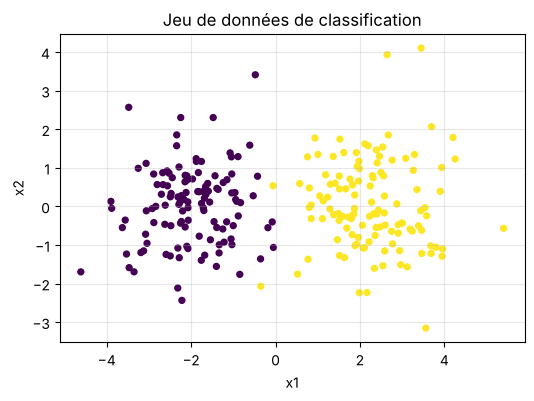

In [26]:
torch.manual_seed(0)

n = 120
class0 = torch.randn(n, 2) + torch.tensor([-2.0, 0.0])
class1 = torch.randn(n, 2) + torch.tensor([ 2.0, 0.0])

X_cls = torch.cat([class0, class1], dim=0)
y_cls = torch.cat([
    torch.zeros(n, dtype=torch.long),
    torch.ones(n, dtype=torch.long)
])

plt.figure(figsize=(6,4))
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Jeu de données de classification")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True, alpha=0.3)
plt.show()

## 16. Modèle de classification

In [27]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.net(x)

model_cls = Classifier()
criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=0.01)

## 17. Entraînement de la classification

In [28]:
losses_cls = []

for epoch in range(250):
    model_cls.train()

    logits = model_cls(X_cls)
    loss = criterion_cls(logits, y_cls)

    optimizer_cls.zero_grad()
    loss.backward()
    optimizer_cls.step()

    losses_cls.append(loss.item())

print("Dernier loss:", losses_cls[-1])

Dernier loss: 0.0006943673361092806


In [29]:
model_cls.eval()
with torch.inference_mode():
    logits = model_cls(X_cls)
    pred = logits.argmax(dim=1)
    accuracy = (pred == y_cls).float().mean()

print(f"Accuracy = {accuracy.item()*100:.2f}%")

Accuracy = 100.00%


Accuracy = 1.0000, recall= 1.0000, precision=1.0000, f1score=1.0000
tensor([[120,   0],
        [  0, 120]])


(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

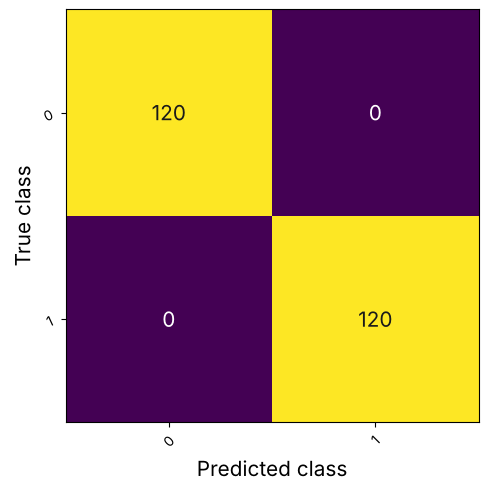

In [30]:
from torcheval.metrics import BinaryAccuracy, BinaryRecall, BinaryPrecision, BinaryPrecision, BinaryF1Score
from torchmetrics.classification import MulticlassConfusionMatrix, BinaryConfusionMatrix
accuracy_metric = BinaryAccuracy()
accuracy_metric.update(y_cls,pred)
accuracy_value = accuracy_metric.compute()

recall_metric = BinaryRecall()
recall_metric.update(y_cls, pred)
recall_value = recall_metric.compute()

precision_metric = BinaryPrecision()
precision_metric.update(y_cls,pred)
precision_value = precision_metric.compute()

f1_score_metric = BinaryF1Score()
f1_score_metric.update(y_cls, pred)
f1_score_value = f1_score_metric.compute()
print(f"Accuracy = {accuracy_value:.4f}, recall= {recall_value:.4f}, precision={precision_value:.4f}, f1score={f1_score_value:.4f}")

metric = BinaryConfusionMatrix()
confusion_matrix = metric(pred, y_cls)
print(confusion_matrix)
metric.plot()

## Visualisation de la frontière de décision

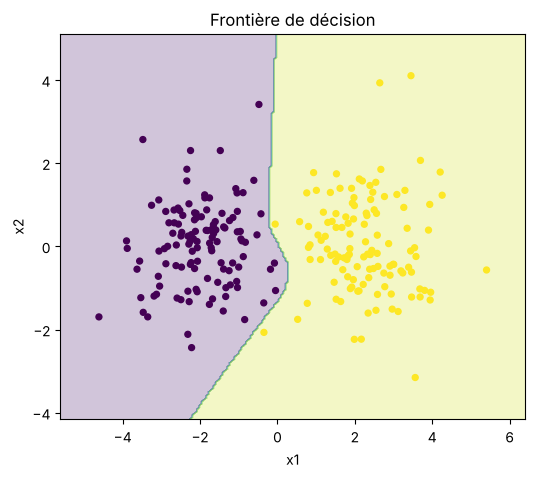

In [31]:
x1_min, x1_max = X_cls[:,0].min()-1, X_cls[:,0].max()+1
x2_min, x2_max = X_cls[:,1].min()-1, X_cls[:,1].max()+1

xx1, xx2 = torch.meshgrid(
    torch.linspace(x1_min, x1_max, 200),
    torch.linspace(x2_min, x2_max, 200),
    indexing='ij'
)

grid = torch.stack([xx1.reshape(-1), xx2.reshape(-1)], dim=1)

model_cls.eval()
with torch.inference_mode():
    zz = model_cls(grid).argmax(dim=1).reshape(xx1.shape)

plt.figure(figsize=(6,5))
plt.contourf(xx1.numpy(), xx2.numpy(), zz.numpy(), alpha=0.25)
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Frontière de décision")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

## 18. Sauvegarder et recharger un modèle

In [32]:
path = "classifier_state_dict.pt"
torch.save(model_cls.state_dict(), path)
print("Modèle sauvegardé dans", path)

new_model = Classifier()
new_model.load_state_dict(torch.load(path, weights_only=True))
new_model.eval()

with torch.inference_mode():
    pred_new = new_model(X_cls).argmax(dim=1)

print("Prédictions identiques:", torch.equal(pred, pred_new))

Modèle sauvegardé dans classifier_state_dict.pt
Prédictions identiques: True


# Synthèse

Les briques essentielles de PyTorch sont maintenant en place :

1. `Tensor`
2. `nn.Module`
3. `forward()`
4. fonction de coût
5. `optimizer.zero_grad()`
6. `loss.backward()`
7. `optimizer.step()`
8. `train()` / `eval()`
9. `Dataset` / `DataLoader`
10. sauvegarde avec `state_dict()`

Cette mécanique reste pratiquement la même pour des modèles plus avancés : CNN, Transformers, modèles génératifs ou PINNs.

# Exercices

### Exercice 1 : Régression

Prédire le salaire selon l’ancienneté et le niveau d’expertise

Objectif:

Construire un modèle de régression linéaire multiple pour prédire le salaire mensuel à partir de deux variables :
- Ancienneté : nombre d’années d’expérience.
- Niveau d’expertise : note de 1 à 5.
Le modèle doit apprendre la relation :

Salaire = w_1 * Ancienneté + w_2 * Expertise + b 

Les salaires sont exprimés en dirhams (DH). Les données sont fictives et servent uniquement à l’apprentissage.

1. *Générer les données*

Pour cet exercice, on suppose que les salaires suivent approximativement la règle : Salaire = 4000 + 600 * Ancienneté + 1500 * Expertise} + Bruit
Le bruit représente les variations individuelles non expliquées par les deux variables.

In [33]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Variations aléatoires des salaires
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = (
    4000
    + 600 * anciennete
    + 1500 * expertise
    + bruit
)

# Matrice des entrées : dimensions (300, 2)
X = torch.cat([anciennete, expertise], dim=1)

# Sortie : dimensions (300, 1)
y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


**Travail demandé**

- Affichez les dimensions de X et de y.
- Calculez le salaire moyen.
- Tracez un nuage de points représentant le salaire selon l’ancienneté, avec une couleur différente selon l’expertise.


Dimensions de X : (300, 2)
Dimensions de y : (300, 1)
Salaire moyen : 15010.55 DH


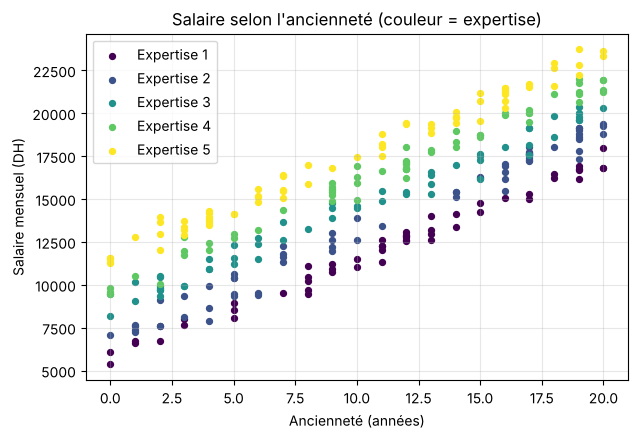

In [34]:
print("Dimensions de X :", tuple(X.shape))
print("Dimensions de y :", tuple(y.shape))
print(f"Salaire moyen : {y.mean().item():.2f} DH")

plt.figure(figsize=(7, 4.5))
couleurs = plt.cm.viridis(torch.linspace(0, 1, 5).numpy())
for niveau in range(1, 6):
    masque = X[:, 1] == niveau
    plt.scatter(X[masque, 0], y[masque, 0], s=18, color=couleurs[niveau - 1],
                label=f"Expertise {niveau}")
plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire mensuel (DH)")
plt.title("Salaire selon l'ancienneté (couleur = expertise)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

2. *Séparer et préparer les données*
Utilisez 80 % des données pour l’entraînement et 20 % pour le test.

Pour faciliter l’apprentissage :

standardisez les entrées à partir des statistiques du jeu d’entraînement ;
exprimez les salaires en milliers de DH.

In [35]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

# Statistiques calculées uniquement sur le jeu d'entraînement
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

3. *Construire et entraîner le modèle*

In [36]:
# Deux variables d'entrée et une sortie
model = nn.Linear(2, 1)

# Erreur quadratique moyenne
criterion = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)

historique = []

model.train()

for epoch in range(500):
    # 1. Réinitialiser les gradients
    optimizer.zero_grad()

    # 2. Prédire les salaires
    predictions = model(X_train_norm)

    # 3. Calculer la perte
    loss = criterion(predictions, y_train)

    # 4. Calculer les gradients
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer.step()

    historique.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Époque {epoch + 1} | "
            f"Perte : {loss.item():.4f}"
        )

Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391
Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391


Travail demandé :

- Complétez le modèle et la boucle d’entraînement.
- Tracez l’évolution de la perte :


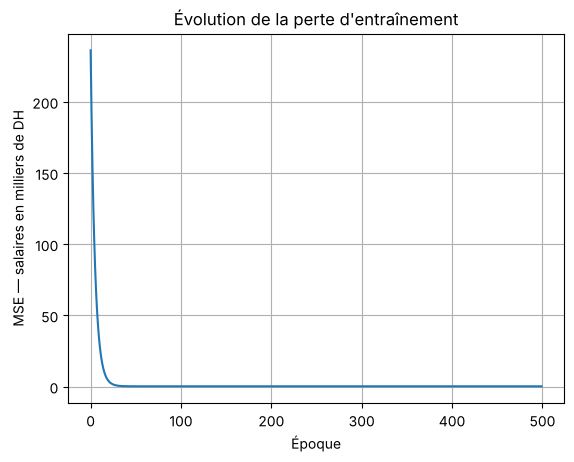

In [37]:
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

4. Évaluer les prédictions

In [38]:
model.eval()

with torch.no_grad():
    predictions_test = model(X_test_norm)

    # Conversion en DH
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000

    # Erreur absolue moyenne
    mae = torch.abs(predictions_dh - salaires_reels_dh).mean()

print(f"Erreur absolue moyenne : {mae.item():.2f} DH")

Erreur absolue moyenne : 381.64 DH


Interprétation : une MAE de 400 DH signifie que les prédictions s’écartent, en moyenne, de 400 DH des salaires réels.

5. Prédire le salaire d’un nouveau salarié

Prédisez le salaire d’une personne ayant :

- 7 ans d’ancienneté ;
- un niveau d’expertise de 4/5.

In [39]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])

# Appliquer la même normalisation qu'à l'entraînement
nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

with torch.no_grad():
    salaire_predit = model(nouveau_salarie_norm) * 1000

print(f"Salaire estimé : {salaire_predit.item():.2f} DH")

Salaire estimé : 14201.94 DH


Vérification : d’après la règle de génération, le salaire sans bruit est :

4000 + 600 * 7 + 1500 * 4 = 14200 DH

Votre prédiction devrait être proche de cette valeur.

Questions complémentaires :

- À expertise constante, quel est l’effet d’une année d’ancienneté supplémentaire ?
- Pourquoi la perte ne devient-elle pas exactement nulle ?
- Le modèle est-il fiable pour une ancienneté de 40 ans, absente des données d’entraînement ?
- Quel effet aurait une augmentation du bruit sur la précision ?
- Retrouvez les coefficients en unités d’origine à partir des paramètres du modèle entraîné. Ils devraient être proches de 600, 1500 et 4000.

Remarque : traiter l’expertise comme une note numérique suppose que chaque passage d’un niveau au suivant a le même effet sur le salaire. Cette hypothèse simplifie l’exercice, mais doit être vérifiée avec des données réelles.

#### Réponses aux questions complémentaires — Exercice 1

**Coefficients en unités d'origine.** Le modèle apprend `y_norm = w_norm · x_norm + b_norm` avec `x_norm = (x − μ)/σ` et `y` en milliers de DH. En remplaçant, on obtient `w = w_norm/σ × 1000` (DH par unité) et `b = (b_norm − Σ w_norm·μ/σ) × 1000` (DH).

In [40]:
w_norm = model.weight.detach()          # forme (1, 2)
b_norm = model.bias.detach()            # forme (1,)

w_dh = (w_norm / ecart_type) * 1000                       # DH par unité
b_dh = (b_norm - (w_norm * moyenne / ecart_type).sum()) * 1000   # DH

print(f"w1 (ancienneté) = {w_dh[0, 0].item():8.1f} DH / an      (valeur de génération : 600)")
print(f"w2 (expertise)  = {w_dh[0, 1].item():8.1f} DH / niveau  (valeur de génération : 1500)")
print(f"b               = {b_dh.item():8.1f} DH             (valeur de génération : 4000)")

# Perte minimale théorique : variance du bruit (500 DH = 0.5 k DH) -> 0.25
with torch.no_grad():
    mse_train = criterion(model(X_train_norm), y_train).item()
    mse_test = criterion(model(X_test_norm), y_test).item()
print(f"\nMSE train = {mse_train:.4f} | MSE test = {mse_test:.4f} | variance du bruit = {0.5**2:.4f} (k DH)²")

# Extrapolation : 40 ans d'ancienneté (hors du domaine 0-20 ans)
with torch.no_grad():
    s40 = model((torch.tensor([[40.0, 4.0]]) - moyenne) / ecart_type) * 1000
print(f"Prédiction pour 40 ans / expertise 4 : {s40.item():.0f} DH")

w1 (ancienneté) =    592.7 DH / an      (valeur de génération : 600)
w2 (expertise)  =   1490.7 DH / niveau  (valeur de génération : 1500)
b               =   4090.3 DH             (valeur de génération : 4000)

MSE train = 0.2391 | MSE test = 0.2217 | variance du bruit = 0.2500 (k DH)²
Prédiction pour 40 ans / expertise 4 : 33760 DH


In [41]:
# Effet d'une augmentation du bruit : on régénère les données avec un bruit plus fort
def mae_selon_bruit(sigma, graine=42):
    g = torch.Generator().manual_seed(graine)
    anc = torch.randint(0, 21, (n, 1), generator=g).float()
    exp = torch.randint(1, 6, (n, 1), generator=g).float()
    sal = 4000 + 600 * anc + 1500 * exp + torch.randn(n, 1, generator=g) * sigma
    Xb, yb = torch.cat([anc, exp], dim=1), sal / 1000
    idx = torch.randperm(n, generator=g)
    tr, te = idx[:limite], idx[limite:]
    mu, sd = Xb[tr].mean(0, keepdim=True), Xb[tr].std(0, keepdim=True)
    m = nn.Linear(2, 1)
    opt = torch.optim.SGD(m.parameters(), lr=0.05)
    for _ in range(500):
        opt.zero_grad()
        nn.MSELoss()(m(((Xb[tr] - mu) / sd)), yb[tr]).backward()
        opt.step()
    with torch.no_grad():
        erreur = torch.abs(m((Xb[te] - mu) / sd) - yb[te]).mean() * 1000
        w1 = (m.weight[0, 0] / sd[0, 0]) * 1000
    return erreur.item(), w1.item()

for sigma in (100, 500, 1500, 3000):
    err, w1 = mae_selon_bruit(sigma)
    print(f"bruit σ = {sigma:5d} DH -> MAE test = {err:7.1f} DH | w1 estimé = {w1:6.1f} (vrai : 600)")

bruit σ =   100 DH -> MAE test =    76.3 DH | w1 estimé =  598.5 (vrai : 600)


bruit σ =   500 DH -> MAE test =   381.6 DH | w1 estimé =  592.7 (vrai : 600)


bruit σ =  1500 DH -> MAE test =  1144.9 DH | w1 estimé =  578.0 (vrai : 600)


bruit σ =  3000 DH -> MAE test =  2289.9 DH | w1 estimé =  556.0 (vrai : 600)


**1. Effet d'une année d'ancienneté supplémentaire (expertise constante).** Le salaire estimé augmente d'environ **w₁ ≈ 600 DH par mois** (voir la cellule ci-dessus). Le modèle étant linéaire, cet effet est le même quelle que soit l'ancienneté de départ.

**2. Pourquoi la perte n'est-elle pas nulle ?** Les salaires contiennent un bruit aléatoire (écart-type 500 DH = 0,5 k DH) que ni l'ancienneté ni l'expertise ne peuvent expliquer. Même avec les bons coefficients, l'erreur quadratique moyenne reste proche de la variance du bruit, soit 0,25 (k DH)². C'est une erreur **irréductible** ; descendre nettement en dessous signalerait du surapprentissage.

**3. Fiabilité à 40 ans d'ancienneté ?** Non. Le modèle n'a vu que des anciennetés de 0 à 20 ans. Il prolonge simplement la droite (le calcul donne un salaire élevé), ce qui est une **extrapolation** sans garantie : dans la réalité les salaires plafonnent, et rien dans les données ne permet de le vérifier.

**4. Effet d'un bruit plus fort.** La MAE augmente à peu près proportionnellement au bruit (environ 0,8 σ), et les coefficients estimés deviennent moins précis, comme le montre la dernière cellule. Le modèle reste correct « en moyenne », mais chaque prédiction individuelle est moins précise.

**5. Remarque sur l'expertise.** Traiter la note comme un nombre impose un effet identique (≈ 1500 DH) entre chaque niveau. Avec des données réelles, on pourrait vérifier cette hypothèse en encodant l'expertise en catégories (one-hot).

###  Exercice 3  — Classification des fleurs Iris 🌸

Objectif : entraîner un réseau de neurones pour prédire l’espèce d’une fleur à partir de quatre mesures :

- longueur et largeur des sépales ;
- longueur et largeur des pétales.

Le jeu de données Iris contient 150 fleurs réparties en trois classes : setosa, versicolor et virginica.


Bibliothèques : torch, scikit-learn.

**1. Préparation des données**

In [42]:
import torch
from torch import nn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

# Charger les données
iris = load_iris()
X, y = iris.data, iris.target

# Séparer les données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Ajuster la normalisation uniquement sur l'entraînement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convertir en tenseurs
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)

Dimensions : torch.Size([120, 4]) torch.Size([120])


**Questions :**

- Que représentent les quatre colonnes de X_train ?
- Pourquoi utilise-t-on torch.long pour les étiquettes ?
- Pourquoi ne faut-il pas ajuster le StandardScaler sur les données de test ?

**2. Construire le réseau**

**Réponses**

- **Les quatre colonnes de `X_train`** sont les mesures d'une fleur (en cm, ensuite standardisées) : longueur du sépale, largeur du sépale, longueur du pétale, largeur du pétale. Chaque ligne est une fleur (120 fleurs d'entraînement).
- **`torch.long` pour les étiquettes** : `CrossEntropyLoss` attend des **indices de classes** (entiers 64 bits : 0, 1 ou 2), et non des flottants. Elle les utilise pour sélectionner le logit de la bonne classe.
- **Pourquoi ne pas ajuster le `StandardScaler` sur le test ?** Calculer moyenne et écart-type avec les données de test ferait « fuiter » de l'information du test vers l'entraînement (*data leakage*). Le test simule des données jamais vues : il doit être transformé avec les statistiques calculées sur l'entraînement uniquement, sinon l'évaluation est trop optimiste.

In [43]:
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

Attention : n’ajoutez pas de Softmax à la sortie. CrossEntropyLoss attend directement les scores bruts, appelés logits.

**3. Entraîner le modèle**

Complétez la boucle d’entraînement. Pour cet exercice, chaque itération utilise toutes les données d’entraînement.

In [44]:
epochs = 200
losses = []

model.train()

for epoch in range(epochs):
    # remettre les gradients à zéro
    optimizer.zero_grad()

    # calculer les scores prédits
    logits = model(X_train)

    # calculer la perte
    loss = criterion(logits, y_train)

    # calculer les gradients
    loss.backward()

    # mettre à jour les paramètres
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525
Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432


**4. Évaluer le classifieur**

Complétez le calcul des prédictions et de l’accuracy, c’est-à-dire la proportion de fleurs correctement classées.

In [45]:
model.eval()

with torch.no_grad():
    logits = model(X_test)

    # sélectionner la classe au score maximal pour chaque fleur
    predictions = logits.argmax(dim=1)

    # calculer la proportion de prédictions correctes
    accuracy = (predictions == y_test).float().mean()

print(f"Accuracy sur le test : {accuracy.item():.1%}")

Accuracy sur le test : 100.0%


**5- Autres question :**

- Tracez la courbe de perte.
- Affichez une matrice de confusion.
- Comparez ce réseau à un modèle sans couche cachée : nn.Linear(4, 3).
- Prédisez l’espèce d’une nouvelle fleur de mesures [5.1, 3.5, 1.4, 0.2], après l’avoir normalisée avec le même scaler.

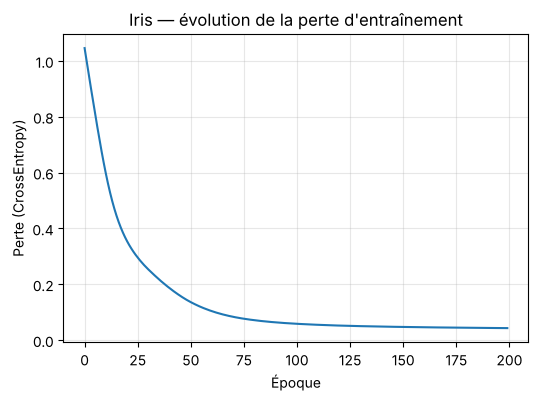

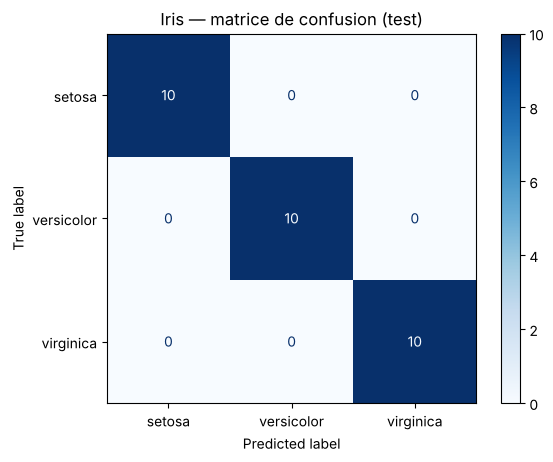

In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 1) Courbe de perte
plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Époque")
plt.ylabel("Perte (CrossEntropy)")
plt.title("Iris — évolution de la perte d'entraînement")
plt.grid(True, alpha=0.3)
plt.show()

# 2) Matrice de confusion sur le jeu de test
ConfusionMatrixDisplay.from_predictions(
    y_test.numpy(), predictions.numpy(),
    display_labels=iris.target_names, cmap="Blues"
)
plt.title("Iris — matrice de confusion (test)")
plt.show()

In [47]:
# 3) Comparaison avec un modèle sans couche cachée : nn.Linear(4, 3)
def entrainer_et_evaluer(modele, epochs=200, lr=0.01):
    critere = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(modele.parameters(), lr=lr)
    modele.train()
    for _ in range(epochs):
        opt.zero_grad()
        critere(modele(X_train), y_train).backward()
        opt.step()
    modele.eval()
    with torch.no_grad():
        acc_train = (modele(X_train).argmax(1) == y_train).float().mean().item()
        acc_test = (modele(X_test).argmax(1) == y_test).float().mean().item()
    return acc_train, acc_test

torch.manual_seed(42)
modele_lineaire = nn.Linear(4, 3)
acc_tr, acc_te = entrainer_et_evaluer(modele_lineaire)
print(f"Modèle linéaire  Linear(4, 3)        : train = {acc_tr:.1%} | test = {acc_te:.1%}")

acc_tr_mlp = (model(X_train).argmax(1) == y_train).float().mean().item()
print(f"Réseau avec couche cachée (4-16-3)   : train = {acc_tr_mlp:.1%} | test = {accuracy.item():.1%}")

Modèle linéaire  Linear(4, 3)        : train = 95.8% | test = 90.0%
Réseau avec couche cachée (4-16-3)   : train = 98.3% | test = 100.0%


In [48]:
# 4) Prédiction d'une nouvelle fleur, normalisée avec le même scaler
nouvelle_fleur = [[5.1, 3.5, 1.4, 0.2]]
nouvelle_fleur_norm = torch.tensor(scaler.transform(nouvelle_fleur), dtype=torch.float32)

model.eval()
with torch.no_grad():
    probas = torch.softmax(model(nouvelle_fleur_norm), dim=1)[0]

classe = probas.argmax().item()
print(f"Espèce prédite : {iris.target_names[classe]} (confiance : {probas[classe].item():.1%})")

Espèce prédite : setosa (confiance : 100.0%)


**Commentaire.** Les trois espèces sont presque séparables par les mesures des pétales : *setosa* est parfaitement isolée, seules *versicolor* et *virginica* peuvent se confondre. Sur le jeu de test (30 fleurs), le réseau 4-16-3 classe tout correctement, alors que le modèle linéaire `Linear(4, 3)` se trompe sur quelques fleurs (voir les accuracies ci-dessus). L'écart ne porte que sur 3 fleurs : avec un test aussi petit il n'est pas très significatif, mais il montre que la couche cachée aide à mieux séparer *versicolor* et *virginica*. La fleur `[5.1, 3.5, 1.4, 0.2]` (pétales très petits) est classée *setosa*.

### Exercice 2 : Classifier les chiffres MNIST
Objectif : utiliser des mini-lots et évaluer un modèle sur des données de test.

Chargement des données

In [49]:
torch.manual_seed(42)
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

#### Travail demandé : 
- Entraînez le modèle pendant 5 époques.
- Utilisez model.train() pendant l’entraînement.
- Évaluez-le avec model.eval() et torch.no_grad().
- Obtenez les classes prédites avec :
   - predicted_classes = outputs.argmax(dim=1)
   - Calculez mes métriques Accuracy, Recall, Precision et f1-Score sur le jeu de test.
   - Afficher la matrice de confusion
   - Affichez quelques images mal classées.
- Sauvegarder et recharger un modèle : réutiliser un réseau entraîné sans recommencer l’apprentissage.

Attention : CrossEntropyLoss attend les sorties brutes du réseau, sans Softmax, et des étiquettes entières.

**1. Entraînement (5 époques, mini-lots de 64)**

In [50]:
epochs = 5
loss_history_mlp = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)                 # logits bruts, sans Softmax
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history_mlp.append(average_loss)
    print(f"Époque {epoch + 1}/{epochs} | Perte : {average_loss:.4f}")

Époque 1/5 | Perte : 0.3448


Époque 2/5 | Perte : 0.1580


Époque 3/5 | Perte : 0.1083


Époque 4/5 | Perte : 0.0812


Époque 5/5 | Perte : 0.0640


**2. Évaluation sur le jeu de test** (`model.eval()` et `torch.no_grad()`)

In [51]:
def predict_all(net, loader):
    """Retourne les classes prédites et les vraies classes de tout le jeu."""
    net.eval()
    toutes_pred, tous_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = net(images)
            predicted_classes = outputs.argmax(dim=1)
            toutes_pred.append(predicted_classes)
            tous_labels.append(labels)
    return torch.cat(toutes_pred), torch.cat(tous_labels)

all_preds, all_labels = predict_all(model, test_loader)
print("Prédictions :", all_preds.shape, "| Vraies classes :", all_labels.shape)

Prédictions : torch.Size([10000]) | Vraies classes : torch.Size([10000])


In [52]:
from torchmetrics.classification import (
    MulticlassAccuracy, MulticlassRecall, MulticlassPrecision,
    MulticlassF1Score, MulticlassConfusionMatrix
)

acc = MulticlassAccuracy(num_classes=10)(all_preds, all_labels)
rec = MulticlassRecall(num_classes=10, average="macro")(all_preds, all_labels)
prec = MulticlassPrecision(num_classes=10, average="macro")(all_preds, all_labels)
f1 = MulticlassF1Score(num_classes=10, average="macro")(all_preds, all_labels)

print(f"Accuracy  = {acc:.4f}")
print(f"Recall    = {rec:.4f}  (moyenne macro sur les 10 classes)")
print(f"Precision = {prec:.4f}  (moyenne macro sur les 10 classes)")
print(f"F1-score  = {f1:.4f}  (moyenne macro sur les 10 classes)")

Accuracy  = 0.9740
Recall    = 0.9740  (moyenne macro sur les 10 classes)
Precision = 0.9745  (moyenne macro sur les 10 classes)
F1-score  = 0.9742  (moyenne macro sur les 10 classes)


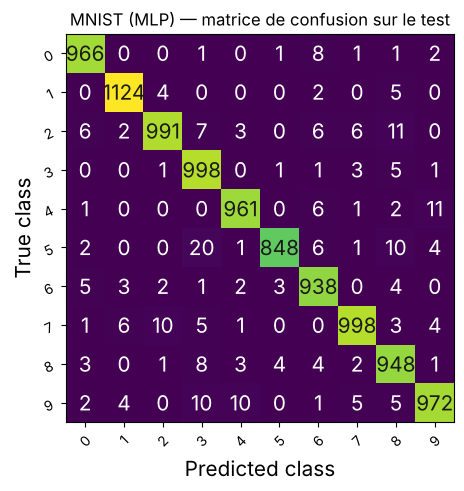

In [53]:
import matplotlib.pyplot as plt

metrique_cm = MulticlassConfusionMatrix(num_classes=10)
matrice = metrique_cm(all_preds, all_labels)
fig, ax = metrique_cm.plot(add_text=True)
ax.set_title("MNIST (MLP) — matrice de confusion sur le test")
plt.show()

256 erreurs sur 10000 images de test


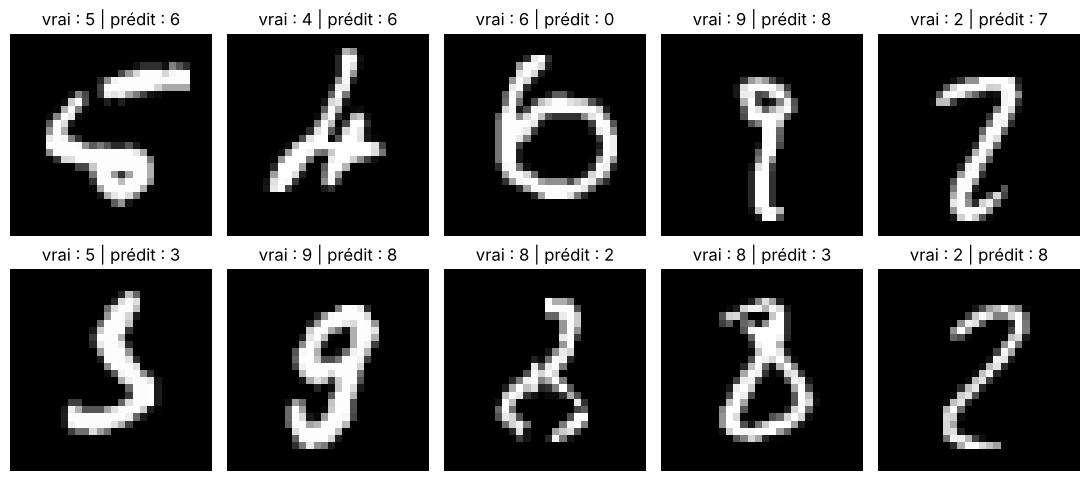

In [54]:
# Quelques images mal classées
indices_erreurs = (all_preds != all_labels).nonzero().squeeze()
print(f"{len(indices_erreurs)} erreurs sur {len(all_labels)} images de test")

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax, idx in zip(axes.flat, indices_erreurs[:10]):
    image, _ = test_dataset[idx.item()]
    ax.imshow(image[0].numpy(), cmap="gray")
    ax.set_title(f"vrai : {all_labels[idx].item()} | prédit : {all_preds[idx].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**3. Sauvegarder puis recharger le modèle** : on réutilise le réseau entraîné sans refaire l'apprentissage. On ne sauvegarde que les paramètres (`state_dict`) ; pour recharger, il faut recréer la même architecture.

In [55]:
torch.save(model.state_dict(), "mnist_mlp.pth")

# Nouvelle instance, mêmes couches, poids aléatoires...
model_recharge = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
# ... remplacés par les poids sauvegardés
model_recharge.load_state_dict(torch.load("mnist_mlp.pth", weights_only=True))

preds_rechargees, _ = predict_all(model_recharge, test_loader)
print("Prédictions identiques après rechargement :", torch.equal(preds_rechargees, all_preds))
print(f"Accuracy du modèle rechargé : {(preds_rechargees == all_labels).float().mean():.2%}")

Prédictions identiques après rechargement : True
Accuracy du modèle rechargé : 97.44%


**Commentaire.** Un simple perceptron multicouche (784-128-10) atteint environ 97 à 98 % d'accuracy en 5 époques. Les erreurs concernent surtout des chiffres qui se ressemblent (4/9, 3/5, 7/2) ou mal écrits, ce que montrent la matrice de confusion et les images mal classées. Comme les classes sont équilibrées, accuracy, rappel, précision et F1 (macro) sont très proches.

### Exercice 4 — Classification MNIST avec un CNN

Objectif : construire un réseau de neurones convolutif (CNN) pour reconnaître les chiffres manuscrits de 0 à 9.

MNIST contient 60 000 images d’entraînement et 10 000 images de test, en niveaux de gris, de taille 28 × 28 pixels.

**1. Chargement des données**

In [56]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

images, labels = next(iter(train_loader))

print("Images :", images.shape)  # [64, 1, 28, 28]
print("Labels :", labels.shape)  # [64]

Appareil : cpu
Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


**Questions :**

- Que représentent les quatre dimensions du tenseur images ?
- Pourquoi mélanger les données d’entraînement avec shuffle=True ?

**Réponses**

- Les quatre dimensions de `images` `[64, 1, 28, 28]` sont : **taille du lot** (64 images), **nombre de canaux** (1 : niveaux de gris, contre 3 pour du RGB), **hauteur** (28) et **largeur** (28).
- **`shuffle=True`** : à chaque époque les images sont présentées dans un ordre différent. Cela évite que les mini-lots soient corrélés (par exemple tous des « 0 » si les données étaient triées), rend le gradient plus représentatif et réduit le risque que le réseau mémorise l'ordre des données.

**2. Visualiser quelques images**

Complétez l’affichage des étiquettes :

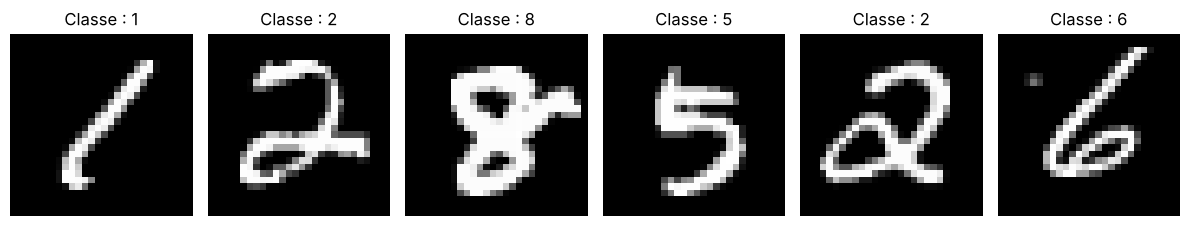

In [57]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    # Annuler la normalisation pour l'affichage
    image = images[i, 0] * 0.3081 + 0.1307

    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**3. Construire le CNN**

Implémentez cette architecture :

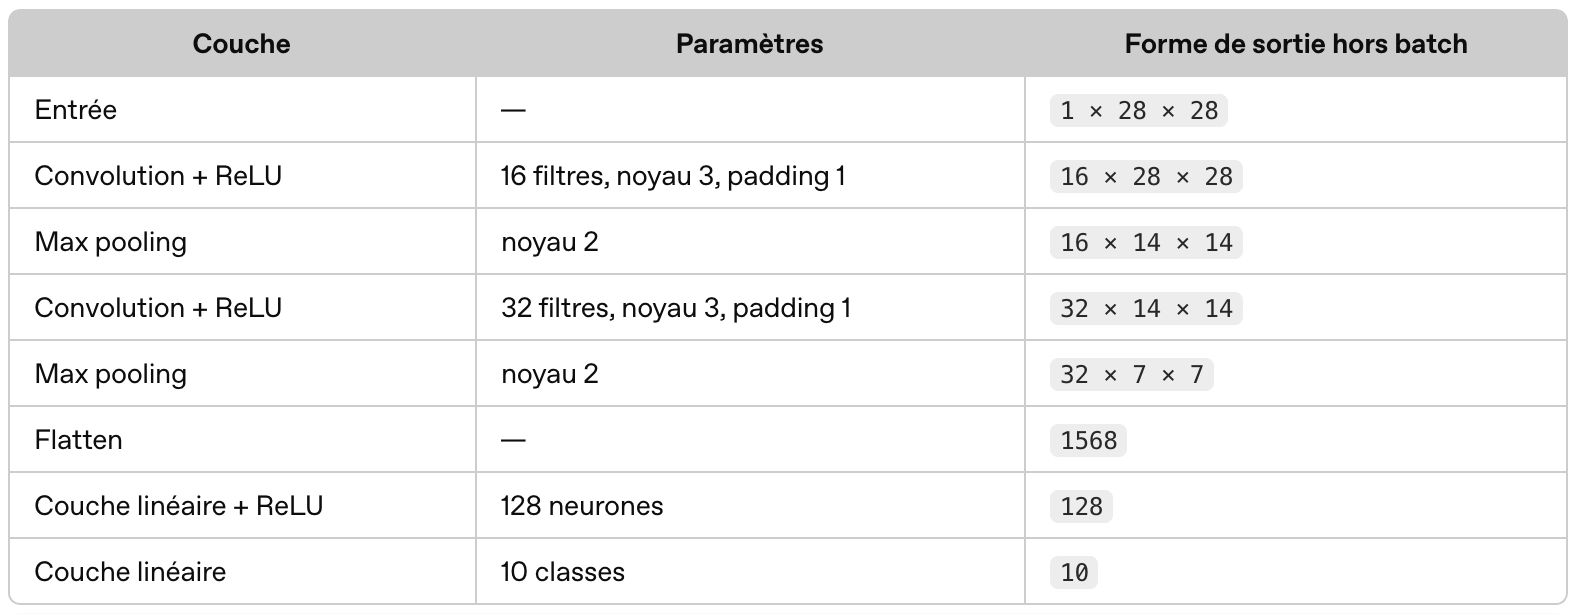

In [58]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = MNISTClassifier().to(device)

# Vérifier la forme de sortie
with torch.no_grad():
    output = model(images.to(device))

assert output.shape == (images.size(0), 10)
print("Sortie :", output.shape)

Sortie : torch.Size([64, 10])


**Question :** pourquoi la première couche linéaire reçoit-elle 32 × 7 × 7 valeurs ?

Attention : n’ajoutez pas de Softmax au modèle. CrossEntropyLoss attend les scores bruts, appelés logits.

**Réponse :** l'image 28 × 28 passe par `Conv2d(…, padding=1)` qui conserve la taille (28 × 28), puis `MaxPool2d(2)` la divise par deux (14 × 14) ; la seconde convolution conserve 14 × 14 et le second pooling donne **7 × 7**. La dernière convolution produit **32 canaux** : le tenseur final est `32 × 7 × 7 = 1568` valeurs par image, qu'on aplatit (`Flatten`) pour la couche linéaire.

**4. Entraîner le réseau**

In [59]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # 1. Réinitialiser les gradients
        optimizer.zero_grad()

        # 2. Calculer les scores
        logits = model(images)

        # 3. Calculer la perte
        loss = criterion(logits, labels)

        # 4. Calculer les gradients
        loss.backward()

        # 5. Mettre à jour les paramètres
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history.append(average_loss)

    print(
        f"Époque {epoch + 1}/{epochs} "
        f"| Perte : {average_loss:.4f}"
    )

Époque 1/3 | Perte : 0.1680


Époque 2/3 | Perte : 0.0480


Époque 3/3 | Perte : 0.0346


**5. Évaluer sur le jeu de test**

In [60]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)

        # Classe ayant le score le plus élevé
        predictions = logits.argmax(dim=1)

        # Compter les bonnes prédictions
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = correct / total
print(f"Accuracy sur le test : {accuracy:.2%}")

Accuracy sur le test : 98.88%


**Indices :**

- argmax(dim=1) sélectionne une classe pour chaque image ;
(predictions == labels).sum().item() compte les prédictions correctes.

- Résultat attendu : une accuracy généralement supérieure à 97 % après quelques époques, sans garantie exacte.

**Autres questions :**

- Affichez 10 images mal classées, avec leur vraie classe et la prédiction.
- Ajoutez une couche Dropout avant la dernière couche linéaire.
- Sauvegardez les paramètres avec torch.save(model.state_dict(), "mnist_cnn.pth").

112 images mal classées sur 10000


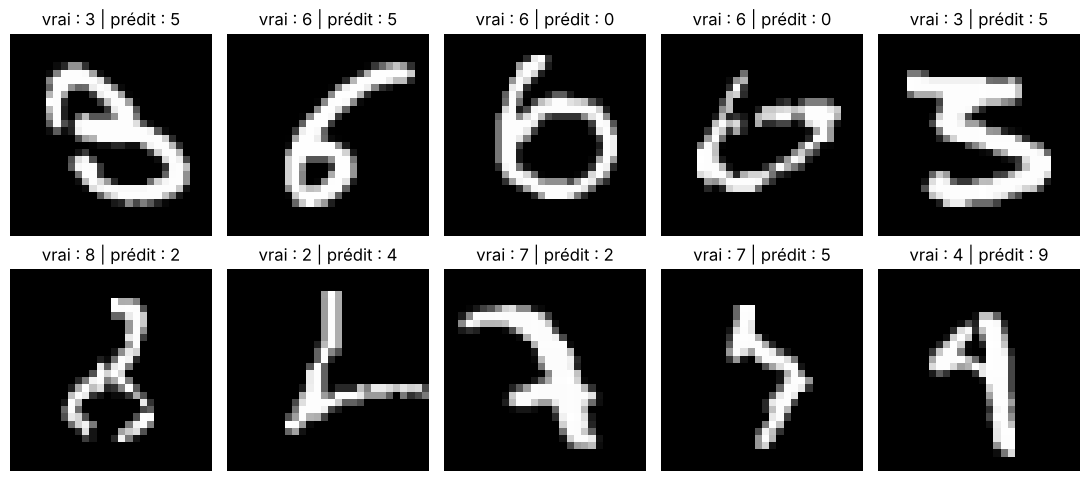

In [61]:
# 1) Dix images mal classées (vraie classe et prédiction)
def predict_all_cnn(net, loader):
    net.eval()
    preds, vrais = [], []
    with torch.no_grad():
        for imgs, labs in loader:
            preds.append(net(imgs.to(device)).argmax(dim=1).cpu())
            vrais.append(labs)
    return torch.cat(preds), torch.cat(vrais)

preds_cnn, vrais_cnn = predict_all_cnn(model, test_loader)
erreurs = (preds_cnn != vrais_cnn).nonzero().squeeze()
print(f"{len(erreurs)} images mal classées sur {len(vrais_cnn)}")

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax, idx in zip(axes.flat, erreurs[:10]):
    img, _ = test_dataset[idx.item()]
    ax.imshow((img[0] * 0.3081 + 0.1307).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"vrai : {vrais_cnn[idx].item()} | prédit : {preds_cnn[idx].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [62]:
# 2) Variante avec Dropout avant la dernière couche linéaire
class MNISTClassifierDropout(MNISTClassifier):
    def __init__(self, p=0.5):
        super().__init__()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p),            # actif seulement en mode train()
            nn.Linear(128, 10)
        )

torch.manual_seed(42)
model_drop = MNISTClassifierDropout().to(device)
optimizer_drop = torch.optim.Adam(model_drop.parameters(), lr=0.001)

for epoch in range(epochs):
    model_drop.train()                # Dropout actif
    total_loss = 0.0
    for imgs, labs in train_loader:
        imgs, labs = imgs.to(device), labs.to(device)
        optimizer_drop.zero_grad()
        loss = criterion(model_drop(imgs), labs)
        loss.backward()
        optimizer_drop.step()
        total_loss += loss.item() * imgs.size(0)
    print(f"[Dropout] Époque {epoch + 1}/{epochs} | Perte : {total_loss / len(train_dataset):.4f}")

preds_drop, _ = predict_all_cnn(model_drop, test_loader)     # eval() : Dropout désactivé
print(f"Accuracy sans Dropout : {(preds_cnn == vrais_cnn).float().mean():.2%}")
print(f"Accuracy avec Dropout : {(preds_drop == vrais_cnn).float().mean():.2%}")

[Dropout] Époque 1/3 | Perte : 0.2337


[Dropout] Époque 2/3 | Perte : 0.0884


[Dropout] Époque 3/3 | Perte : 0.0657


Accuracy sans Dropout : 98.88%
Accuracy avec Dropout : 98.86%


In [63]:
# 3) Sauvegarde des paramètres puis rechargement
torch.save(model.state_dict(), "mnist_cnn.pth")

model_cnn_recharge = MNISTClassifier().to(device)
model_cnn_recharge.load_state_dict(torch.load("mnist_cnn.pth", map_location=device, weights_only=True))

preds_rechargees_cnn, _ = predict_all_cnn(model_cnn_recharge, test_loader)
print("Prédictions identiques après rechargement :", torch.equal(preds_rechargees_cnn, preds_cnn))

Prédictions identiques après rechargement : True


**Commentaire.** Le CNN dépasse nettement le MLP (accuracy autour de 98,5–99 % dès 3 époques) car les convolutions exploitent la structure spatiale de l'image et partagent leurs poids, avec bien moins de paramètres par couche. Le Dropout agit comme régularisation : il rend l'entraînement plus bruité, mais son effet sur l'accuracy est ici faible puisque le CNN ne surapprend pas encore après 3 époques. Il est désactivé automatiquement par `model.eval()`.